# Лабораторная работа 2

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from digits_data import load_variant2
np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['image.cmap'] = 'gray'

from scripts.classifiers.neural_net import TwoLayerNet

def rel_error(x, y):
    return np.max(np.abs(x-y) / np.maximum(1e-8, np.abs(x)+np.abs(y)))


1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [2]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных. 

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [3]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [4]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.794120407794253e-13


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2. 


In [5]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447646e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738422e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


Toy final loss: 0.0005261511635001559


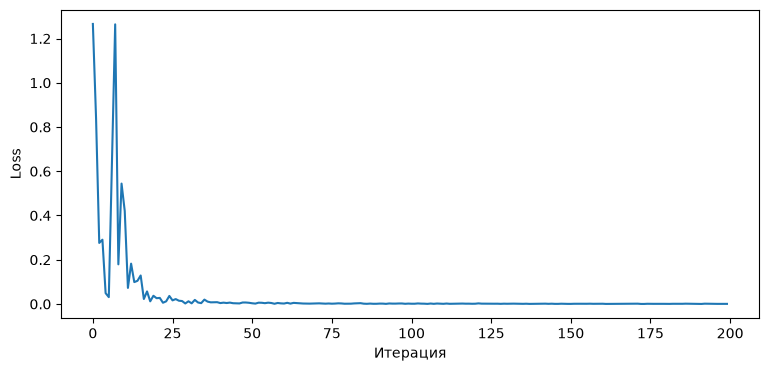

In [6]:
net = init_toy_model()
stats = net.train(X, y, X, y, learning_rate=0.1, reg=5e-6, num_iters=200, batch_size=5, learning_rate_decay=1.0)
print('Toy final loss:', stats['loss_history'][-1])
assert stats['loss_history'][-1] < 0.02
plt.plot(stats['loss_history']); plt.xlabel('Итерация'); plt.ylabel('Loss'); plt.show()


# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту. 

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1. 

Обучите нейронную сеть на ваших данных. 

При сдаче лабораторной работы объясните значения всех параметров метода train.

In [7]:
data = load_variant2()
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']
print('train/val/test:', X_train.shape, X_val.shape, X_test.shape)
np.random.seed(42)
net = TwoLayerNet(64, 50, 10, std=0.1)
stats = net.train(X_train, y_train, X_val, y_val, num_iters=1500, batch_size=64,
                  learning_rate=0.1, learning_rate_decay=0.99, reg=1e-4)
print('Baseline val:', np.mean(net.predict(X_val) == y_val))


train/val/test: (1077, 64) (360, 64) (360, 64)


Baseline val: 0.9611111111111111


Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29. 

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др. 

Для лучшей модели вычислите acсuracy на тестовом наборе. 

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков. 

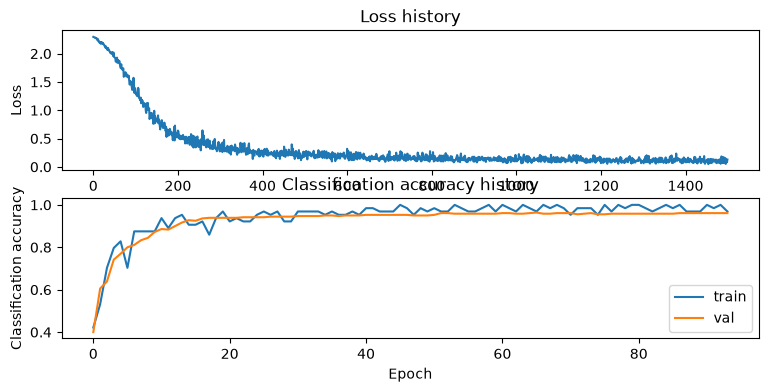

In [8]:
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.show()

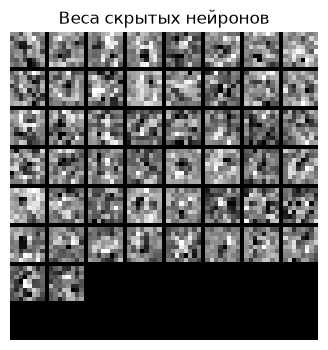

In [9]:
from scripts.vis_utils import visualize_grid
weights = net.params['W1'].T.reshape(-1, 8, 8, 1)
plt.imshow(visualize_grid(weights).squeeze()); plt.title('Веса скрытых нейронов'); plt.axis('off'); plt.show()


Сделайте выводы по результатам работы. 

hidden=32, lr=0.05, reg=0.0001: val=0.9583
hidden=32, lr=0.05, reg=0.001: val=0.9528


hidden=32, lr=0.15, reg=0.0001: val=0.9722
hidden=32, lr=0.15, reg=0.001: val=0.9778


hidden=64, lr=0.05, reg=0.0001: val=0.9611
hidden=64, lr=0.05, reg=0.001: val=0.9583


hidden=64, lr=0.15, reg=0.0001: val=0.9750
hidden=64, lr=0.15, reg=0.001: val=0.9778


hidden=128, lr=0.05, reg=0.0001: val=0.9694


hidden=128, lr=0.05, reg=0.001: val=0.9667


hidden=128, lr=0.15, reg=0.0001: val=0.9750


hidden=128, lr=0.15, reg=0.001: val=0.9778
Best hidden/lr/reg: (32, 0.15, 0.001) val: 0.9777777777777777 test: 0.9583333333333334


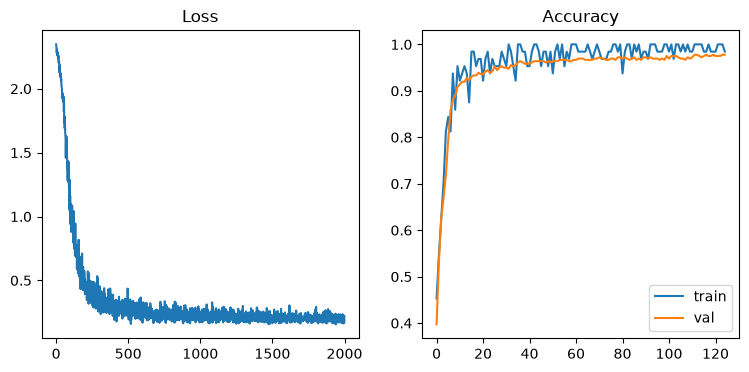

In [10]:
experiments = []; best_val = -1
for hidden in [32, 64, 128]:
    for lr in [0.05, 0.15]:
        for reg in [1e-4, 1e-3]:
            np.random.seed(42)
            candidate = TwoLayerNet(64, hidden, 10, std=0.1)
            history = candidate.train(X_train, y_train, X_val, y_val,
                       learning_rate=lr, learning_rate_decay=0.995, reg=reg,
                       num_iters=2000, batch_size=64)
            val_acc = np.mean(candidate.predict(X_val) == y_val)
            experiments.append((hidden, lr, reg, val_acc))
            print(f'hidden={hidden}, lr={lr}, reg={reg}: val={val_acc:.4f}')
            if val_acc > best_val:
                best_val, best_net, best_history, best_config = val_acc, candidate, history, (hidden, lr, reg)
test_acc = np.mean(best_net.predict(X_test) == y_test)
print('Best hidden/lr/reg:', best_config, 'val:', best_val, 'test:', test_acc)
fig, axes = plt.subplots(1, 2)
axes[0].plot(best_history['loss_history']); axes[0].set_title('Loss')
for split in ['train', 'val']:
    axes[1].plot(best_history[split + '_acc_history'], label=split)
axes[1].set_title('Accuracy'); axes[1].legend(); plt.show()


**Вариант 2.** Используется `sklearn.datasets.load_digits` (1797 цифр 8×8),
указанный в методических материалах под названием MNIST. Это отдельный набор,
не полный MNIST 28×28. Во всех работах одно стратифицированное разбиение
60/20/20 с `random_state=42`. Гиперпараметры выбираются без тестовой выборки.
Интенсивности делятся на 16; среднее для центрирования считается только по train.

**Параметры train.** `learning_rate` — длина шага SGD;
`learning_rate_decay` — множитель шага после эпохи; `reg` — коэффициент L2;
`num_iters` — число обновлений; `batch_size` — число примеров в случайном мини-батче;
`verbose` — печать прогресса. `X, y` задают обучение, `X_val, y_val` — контроль.
В этой работе ровно один скрытый слой: меняются его ширина, шаг и L2,
а более глубокие сети исследуются в ЛР 3.

**Вывод.** Реализованы affine–ReLU–affine и стабильная softmax cross-entropy.
Проверки эталонных scores, loss и численных градиентов приведены выше.
На модельных данных достигнута loss < 0.02. Поиск 12 конфигураций выполнен по val;
тестовая оценка рассчитана только для выбранной сети. Графики показывают,
как снижение обучающей ошибки сопровождается изменением точности на отложенных данных.


**Результат запуска.** Toy loss=0.000526 < 0.02. Из 12 конфигураций выбрана сеть 64→32→10, lr=0.15, reg=0.001: val 97,78%, test 95,83%. Более широкие сети не улучшили лучшую val, поэтому достаточно 32 скрытых нейронов.
